# Первичный анализ набора данных

Датасет: IBM HR Analytics Employee Attrition & Performance.
Задача: бинарная классификация (уволится сотрудник или нет).

Выполнил: Гегечкори Георгий

## 1 Загрузка данных и библиотек

In [ ]:
!pip install -q opendatasets legacy-cgi
import opendatasets as od
od.download("https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset")

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/content/ibm-hr-analytics-attrition-dataset/WA_Fn-UseC_-HR-Employee-Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 2 Общая информация

In [3]:
df.shape

(1470, 35)

In [4]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [6]:
df.describe()  # среднее, медиана, квартили, минимум и максимум

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [7]:
df.describe(exclude="number")  # категориальные признаки: число уникальных, самое частое значение и его частота

,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime
count,1470,1470,1470,1470,1470,1470,1470,1470,1470
unique,2,3,3,6,2,9,3,1,2
top,No,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No
freq,1233,1043,961,606,882,326,673,1470,1054


## 3 Пропущенные значения

In [8]:
df.isna().sum()  # количество пропусков по столбцам

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [9]:
(df.isna().mean() * 100).round(2)  # доля пропусков в процентах

Age                         0.0
Attrition                   0.0
BusinessTravel              0.0
DailyRate                   0.0
Department                  0.0
DistanceFromHome            0.0
Education                   0.0
EducationField              0.0
EmployeeCount               0.0
EmployeeNumber              0.0
EnvironmentSatisfaction     0.0
Gender                      0.0
HourlyRate                  0.0
JobInvolvement              0.0
JobLevel                    0.0
JobRole                     0.0
JobSatisfaction             0.0
MaritalStatus               0.0
MonthlyIncome               0.0
MonthlyRate                 0.0
NumCompaniesWorked          0.0
Over18                      0.0
OverTime                    0.0
PercentSalaryHike           0.0
PerformanceRating           0.0
RelationshipSatisfaction    0.0
StandardHours               0.0
StockOptionLevel            0.0
TotalWorkingYears           0.0
TrainingTimesLastYear       0.0
WorkLifeBalance             0.0
YearsAtC

## 4 Дубликаты

In [10]:
df.duplicated().sum()  # число полных копий сверх первого вхождения

np.int64(0)

In [11]:
df["EmployeeNumber"].duplicated().sum()  # повторы идентификатора сотрудника

np.int64(0)

In [12]:
#df[df.duplicated(keep=False)].head(10)  # примеры, включая первые вхождения

## 5 Уникальные значения и константные признаки

In [13]:
df.nunique()  # число уникальных непустых значений каждого столбца

Age                           43
Attrition                      2
BusinessTravel                 3
DailyRate                    886
Department                     3
DistanceFromHome              29
Education                      5
EducationField                 6
EmployeeCount                  1
EmployeeNumber              1470
EnvironmentSatisfaction        4
Gender                         2
HourlyRate                    71
JobInvolvement                 4
JobLevel                       5
JobRole                        9
JobSatisfaction                4
MaritalStatus                  3
MonthlyIncome               1349
MonthlyRate                 1427
NumCompaniesWorked            10
Over18                         1
OverTime                       2
PercentSalaryHike             15
PerformanceRating              2
RelationshipSatisfaction       4
StandardHours                  1
StockOptionLevel               4
TotalWorkingYears             40
TrainingTimesLastYear          7
WorkLifeBa

In [14]:
unique_counts = df.nunique()
unique_counts[unique_counts <= 1]  # столбцы с одним значением или без значений

EmployeeCount    1
Over18           1
StandardHours    1
dtype: int64

Три столбца — `EmployeeCount`, `Over18`, `StandardHours` — содержат одно значение на всю таблицу и никакой информации не несут.
`EmployeeNumber` уникален в каждой строке: это идентификатор, а не признак.

## 6 Баланс классов

In [15]:
df["Attrition"].value_counts(dropna=False)  # количество объектов, включая пропуски

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [16]:
(df["Attrition"].value_counts(normalize=True) * 100).round(2) # доли рассчитаны среди строк с известной меткой.

Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64

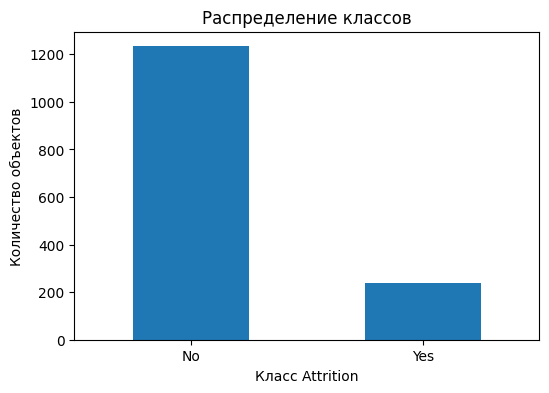

In [17]:
df["Attrition"].value_counts().plot(kind="bar", figsize=(6, 4))
plt.title("Распределение классов")
plt.xlabel("Класс Attrition")
plt.ylabel("Количество объектов")
plt.xticks(rotation=0)
plt.show()

Классы несбалансированы: уволившихся около 16 %. Модель, которая всегда отвечает «No», получит accuracy около 84 %, не найдя ни одного уволившегося — поэтому качество будем оценивать по recall и precision.

## 7 Распределения числовых признаков

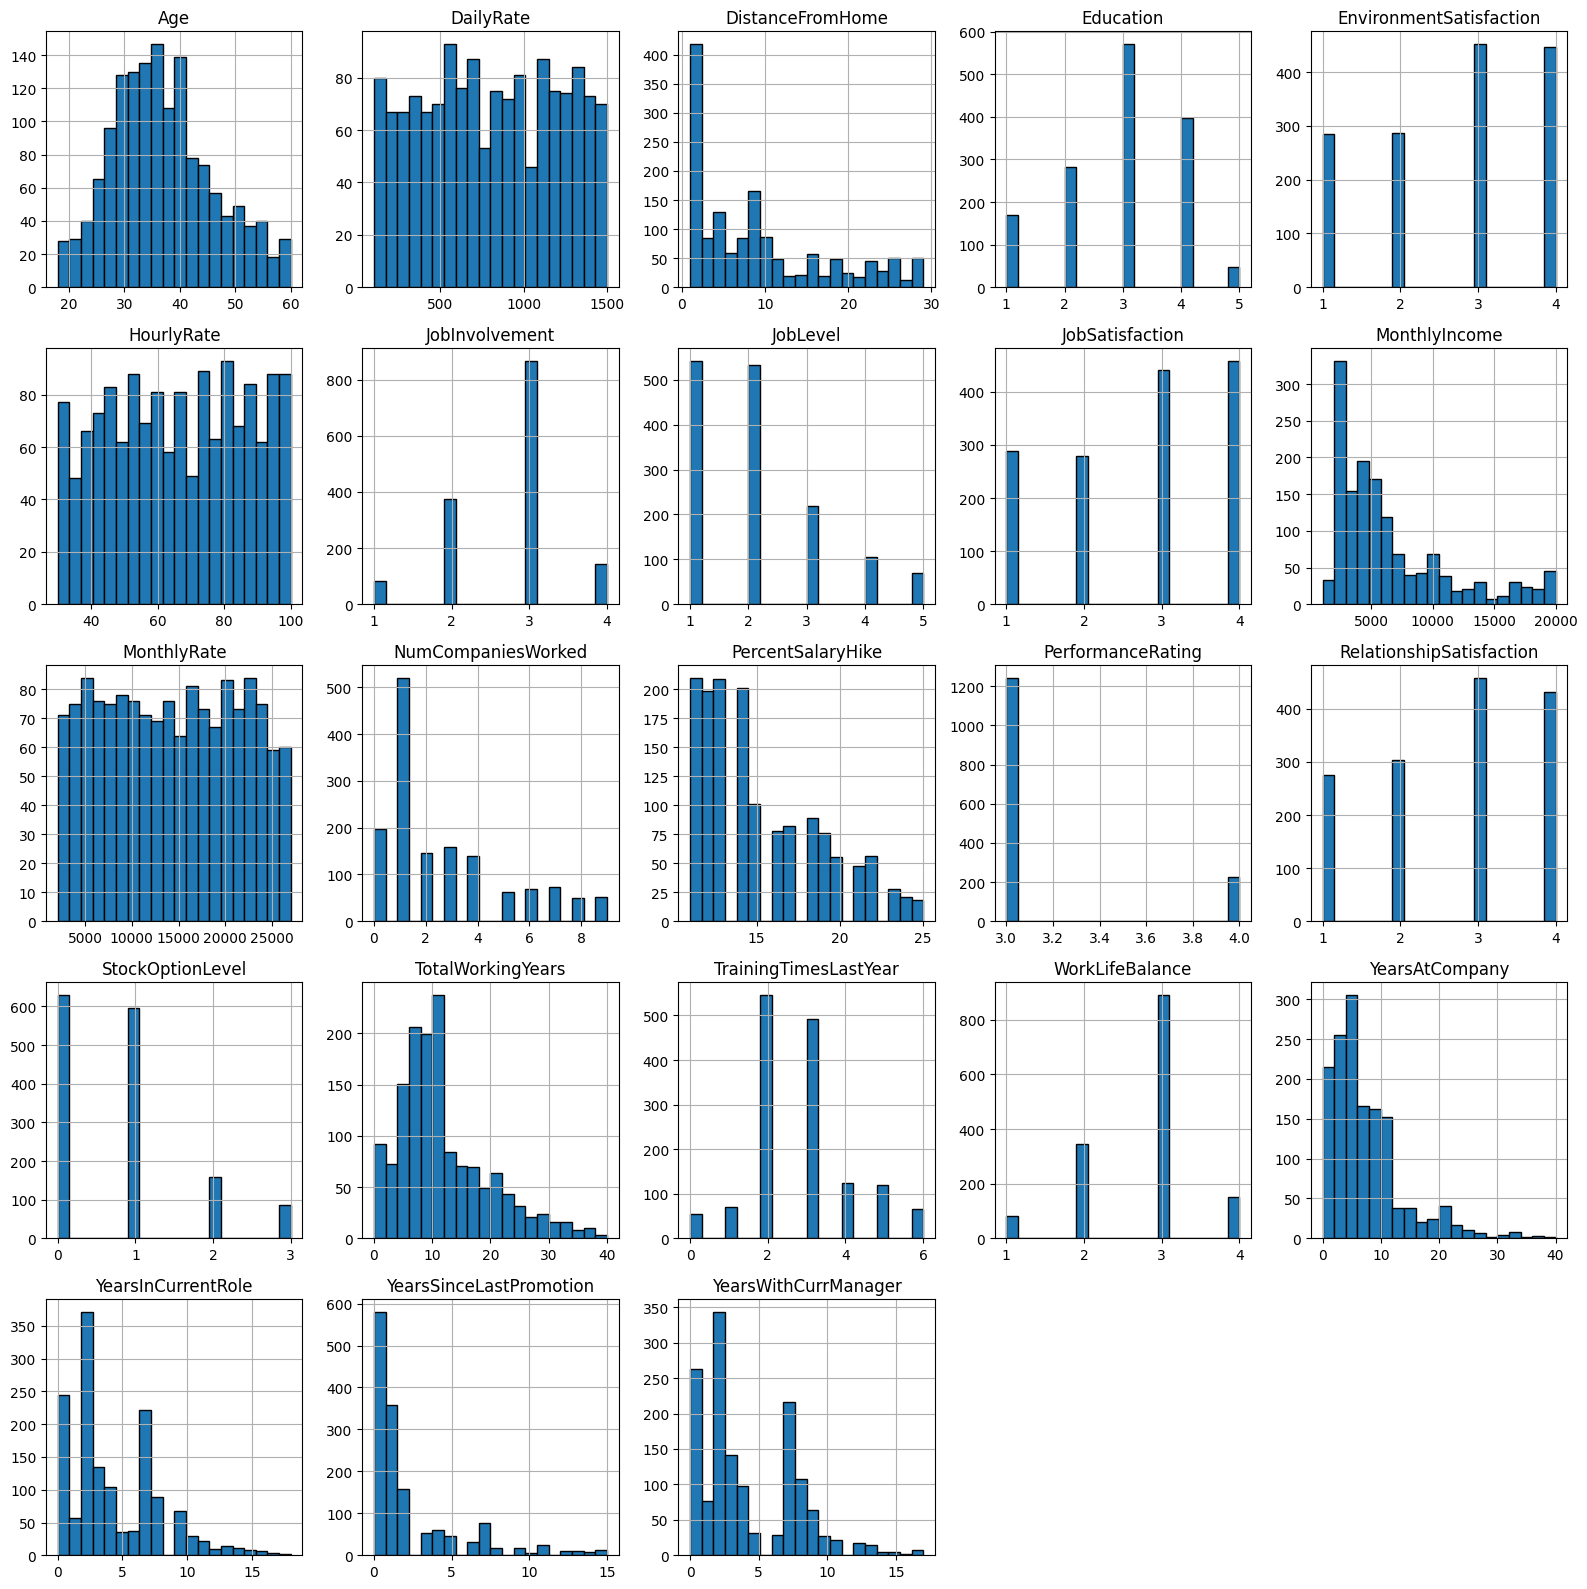

In [18]:
numeric_df = df.select_dtypes(include="number")
features = numeric_df.drop(columns=["EmployeeCount", "StandardHours", "EmployeeNumber"], errors="ignore")
features.hist(bins=20, figsize=(16, 16), edgecolor="black")
plt.tight_layout()
plt.show()

## 8 Boxplot одного признака

Для другого признака достаточно изменить значение column.

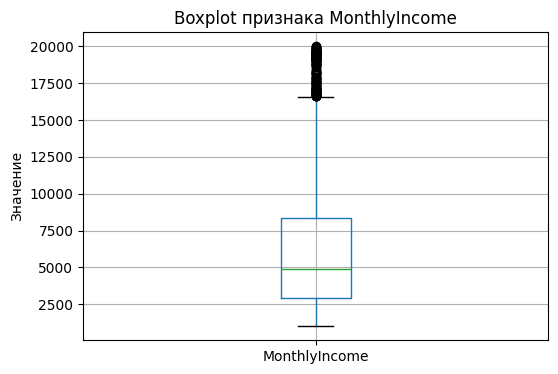

In [19]:
column = "MonthlyIncome"
df.boxplot(column=column, figsize=(6, 4))
plt.title(f"Boxplot признака {column}")
plt.ylabel("Значение")
plt.show()

Линия внутри ящика — медиана, ящик охватывает центральные 50% значений. Отдельные точки за усами — потенциальные выбросы

In [20]:
# число потенциальных выбросов по правилу 1,5 IQR
q1, q3 = df[column].quantile([0.25, 0.75])
iqr = q3 - q1
((df[column] < q1 - 1.5 * iqr) | (df[column] > q3 + 1.5 * iqr)).sum()

np.int64(114)

Высокие доходы здесь — не ошибка, а руководители и старшие специалисты, поэтому удалять их не нужно.

## 9 Категориальные признаки

Для другого признака достаточно изменить значение column.

In [21]:
categorical = df.select_dtypes(exclude="number").columns
categorical

Index(['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender',
       'JobRole', 'MaritalStatus', 'Over18', 'OverTime'],
      dtype='str')

In [22]:
column = "OverTime"
(pd.crosstab(df[column], df["Attrition"], normalize="index") * 100).round(1)  # доля увольнений внутри каждой категории, %

Attrition,No,Yes
OverTime,,
No,89.6,10.4
Yes,69.5,30.5


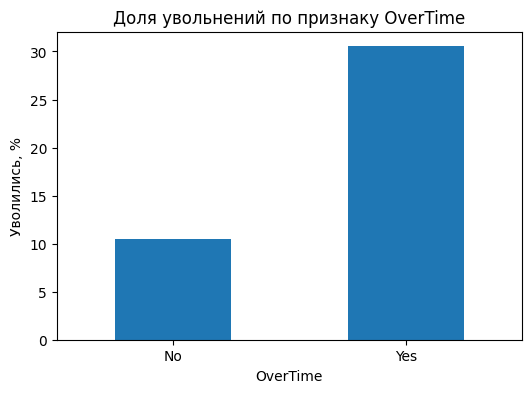

In [23]:
(pd.crosstab(df[column], df["Attrition"], normalize="index")["Yes"] * 100).plot(kind="bar", figsize=(6, 4))
plt.title(f"Доля увольнений по признаку {column}")
plt.xlabel(column)
plt.ylabel("Уволились, %")
plt.xticks(rotation=0)
plt.show()

## 10 Краткий итог аудита

In [24]:
print("Количество строк:", len(df))
print("Количество столбцов:", len(df.columns))
print("Пропущенных ячеек:", df.isna().sum().sum())
print("Полных копий:", df.duplicated().sum())
print("Константных столбцов:", list(unique_counts[unique_counts <= 1].index))
print("Доля класса Yes, %:", round((df["Attrition"] == "Yes").mean() * 100, 2))

Количество строк: 1470
Количество столбцов: 35
Пропущенных ячеек: 0
Полных копий: 0
Константных столбцов: ['EmployeeCount', 'Over18', 'StandardHours']
Доля класса Yes, %: 16.12


## 11 Предобработка данных

In [25]:
# df = df.fillna(df.median()) # если есть пропуски заполняем — в этом датасете пропусков нет

# df[df.duplicated()] # посмотреть сами дубли
# df = df.drop_duplicates() # удаление дубликатов — в этом датасете дубликатов нет

In [26]:
df = df.drop(columns=["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber"])  # константы и идентификатор
df["Attrition"] = (df["Attrition"] == "Yes").astype(int)  # целевая переменная: 1 — уволился, 0 — остался
df.shape

(1470, 31)

In [27]:
df["Attrition"].value_counts()

Attrition
0    1233
1     237
Name: count, dtype: int64